# Walkthrough: dimensional facial expression analysis with geometric features

This notebook goes through the whole method end to end using the package's own functions:

1. **Data:** MorphSet, its persons and its generated labels
2. **Pipeline:** landmarks → Procrustes → frontalization → pairwise distances
3. **Training:** PLS(31) with a person-wise split
4. **Evaluation:** CCC on held-out persons, and why splitting by person matters
5. **Interpretation:** which facial movements the linear model responds to
6. **Use:** prediction on a photo

Run it from the repository root with the notebook extra installed:
`uv run --extra notebooks jupyter lab notebooks/walkthrough.ipynb`.
MorphSet (≈ 40 MB) and the dlib model (≈ 100 MB) download on first use. It takes about 2 minutes.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from facial_expression_analysis import (
    DlibLandmarkDetector,
    EmotionEstimator,
    Frontalizer,
    PairwiseDistanceFeatures,
    load_image,
    procrustes_normalize,
)
from facial_expression_analysis.training import TrainConfig, train_model
from facial_expression_analysis.training.data import load_morphset
from facial_expression_analysis.training.metrics import ccc
from facial_expression_analysis.viz import annotate_image, plot_landmarks

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
warnings.filterwarnings("ignore", message="IProgress not found")
ROOT = Path.cwd() if (Path.cwd() / "examples").is_dir() else Path.cwd().parent  # repo root

## 1. Data: MorphSet

MorphSet morphs each person's neutral face towards their posed expressions in 10 steps.
The label of a morph points in the circumplex direction of its expression (or blend of two
expressions), with a radius that grows with the morph step. Each row holds the 68 dlib
landmarks of one image. Every image also has a mirrored copy.

In [2]:
data = load_morphset()
meta = data.meta
print(f"{len(data):,} rows = {(~meta.mirrored).sum():,} images + mirrored copies")
print(f"{meta.subject.nunique()} subject ids, but {meta.person.nunique()} distinct people")
meta.groupby("dataset", observed=True).person.nunique().rename("persons").to_frame().T

166,382 rows = 83,191 images + mirrored copies
711 subject ids, but 337 distinct people


dataset,F,K,R,W
persons,171,70,67,29


max |I - radius| = 3.3306690738754696e-16


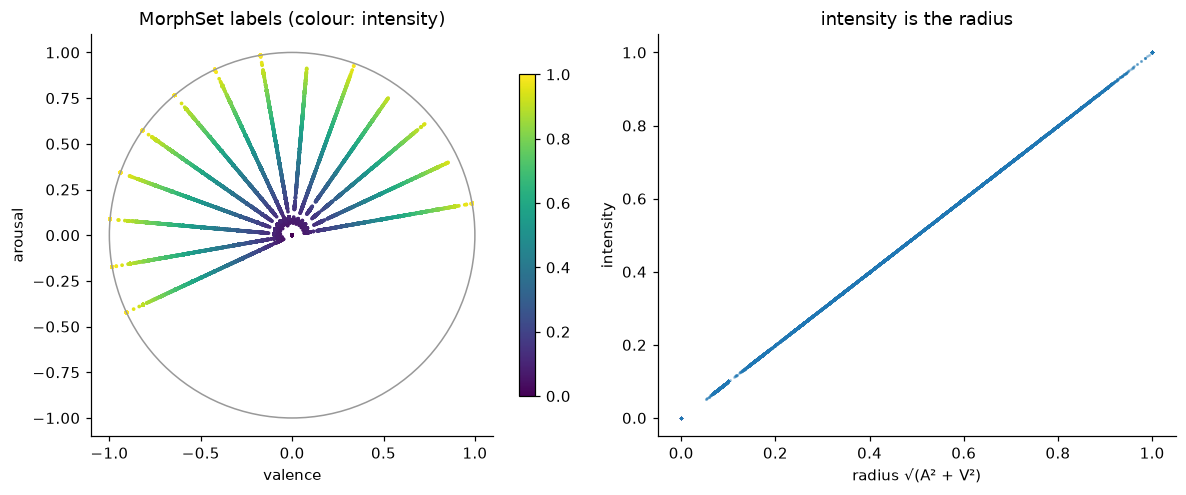

In [3]:
A, V, intensity = data.targets.T
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
sel = np.random.default_rng(0).choice(len(data), 20_000, replace=False)
sc = axes[0].scatter(V[sel], A[sel], c=intensity[sel], s=2, cmap="viridis")
axes[0].add_patch(plt.Circle((0, 0), 1, fill=False, color="0.6"))
axes[0].set(
    xlabel="valence",
    ylabel="arousal",
    aspect="equal",
    xlim=(-1.1, 1.1),
    ylim=(-1.1, 1.1),
    title="MorphSet labels (colour: intensity)",
)
fig.colorbar(sc, ax=axes[0], shrink=0.8)
axes[1].scatter(np.hypot(A, V)[sel], intensity[sel], s=1, alpha=0.3)
axes[1].set(xlabel="radius √(A² + V²)", ylabel="intensity", title="intensity is the radius")
plt.tight_layout()
print("max |I - radius| =", np.abs(intensity - np.hypot(A, V)).max())

The labels cover angles from about 10° (happy) to 205° (sad). The low-arousal, positive
quadrant (calm, relaxed) has no targets: a known limitation of the data.

## 2. The geometric pipeline

Head position, size and in-plane rotation are removed (Procrustes). A linear model then
estimates the frontal view of the shape, and the features are the distances between all pairs
of the 51 non-jaw landmarks, divided by a scale measured on expression-stable points.

1275 features from 51 landmarks; scale from landmarks [27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 39, 42, 45]


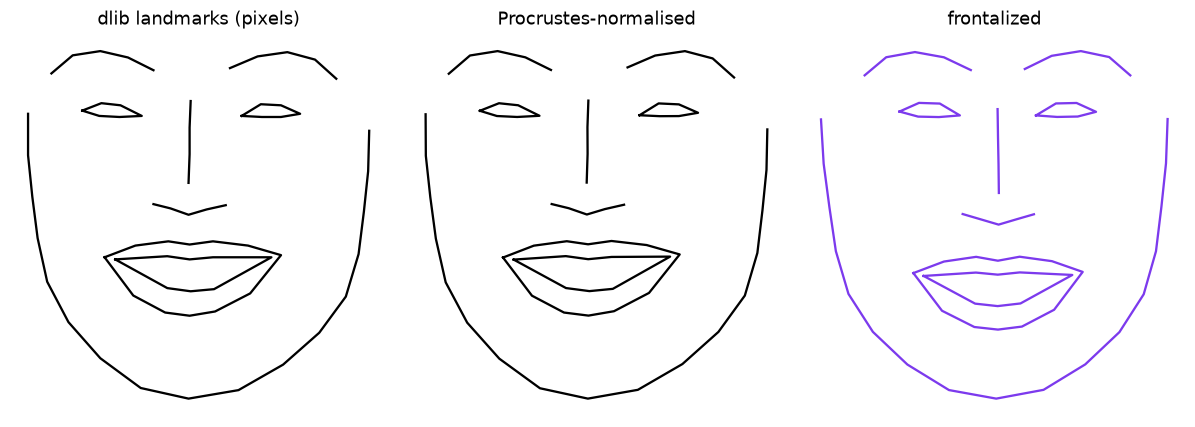

In [4]:
idx = np.flatnonzero((meta.label == "HA").to_numpy() & (data.targets[:, 2] > 0.9))[0]
raw = data.landmarks[idx]
norm = procrustes_normalize(raw)
frontal = Frontalizer()(raw)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
plot_landmarks(raw, axes[0], title="dlib landmarks (pixels)")
plot_landmarks(norm, axes[1], title="Procrustes-normalised")
plot_landmarks(frontal, axes[2], color="#7c3aed", title="frontalized")
plt.tight_layout()

features = PairwiseDistanceFeatures()
print(
    f"{features.n_features} features from {len(features.landmark_indices)} landmarks;",
    "scale from landmarks",
    features.scale_indices.tolist(),
)

## 3. Training PLS(31) with a person-wise split

`train_model` frontalizes all faces, computes the features and fits PLS with 31 components on
70% of the **persons**, keeping 20% for validation and 10% for testing. Mirrored copies stay
with their original, and the photo series of one person stay together.

In [5]:
%%time
result = train_model(data, TrainConfig(n_components=31))
test = result.metrics["test"]
print(f"test: {test['n_samples']:,} faces of {test['n_persons']} unseen persons")
{k: round(v["ccc"], 3) for k, v in test["pipeline"].items()}

test: 17,668 faces of 34 unseen persons
CPU times: user 31.1 s, sys: 529 ms, total: 31.6 s
Wall time: 31.5 s


{'arousal': 0.606, 'valence': 0.791, 'intensity': 0.645}

## 4. Why the split must be by person

MorphSet's `subject` column identifies photo series, not people. Splitting by subject puts
other photos of the same people in the test set, so the model is partly tested on faces it
has already seen. The cell below compares the two splits with the same model (3-fold CV on
the original images, without the mirrored copies, to keep it quick).

In [6]:
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import GroupKFold

from facial_expression_analysis.training import compute_features

orig = ~meta.mirrored.to_numpy()
X = compute_features(data.landmarks[orig])
y = data.targets[orig]


def cv_ccc(groups, n_splits=3):
    scores = []
    for tr, te in GroupKFold(n_splits).split(X, y, groups):
        pred = PLSRegression(31).fit(X[tr], y[tr]).predict(X[te])
        scores.append([ccc(y[te, k], pred[:, k]) for k in range(3)])
    s = np.asarray(scores)
    return s.mean(0), s.std(0)


subject_ids = (meta.dataset.astype(str) + "_" + meta.subject.astype(str))[orig]
for name, groups in {
    "by subject id (leaks)": subject_ids.factorize()[0],
    "by person (correct)": meta.person.to_numpy()[orig],
}.items():
    m, s = cv_ccc(groups)
    print(
        f"{name:22s}",
        "  ".join(f"{t} {a:.3f}±{b:.3f}" for t, a, b in zip("AVI", m, s, strict=True)),
    )

by subject id (leaks)  A 0.638±0.009  V 0.814±0.003  I 0.670±0.005


by person (correct)    A 0.627±0.014  V 0.804±0.005  I 0.659±0.003


## 5. What the model looks at

The exported model is one affine map from distances to (A, V, I). To see it as facial
movement, regress the frontalized landmarks on each prediction across all faces: the slope is
the shape change that accompanies one unit more of that output (as in
`experiments/11_interpretability.py`).

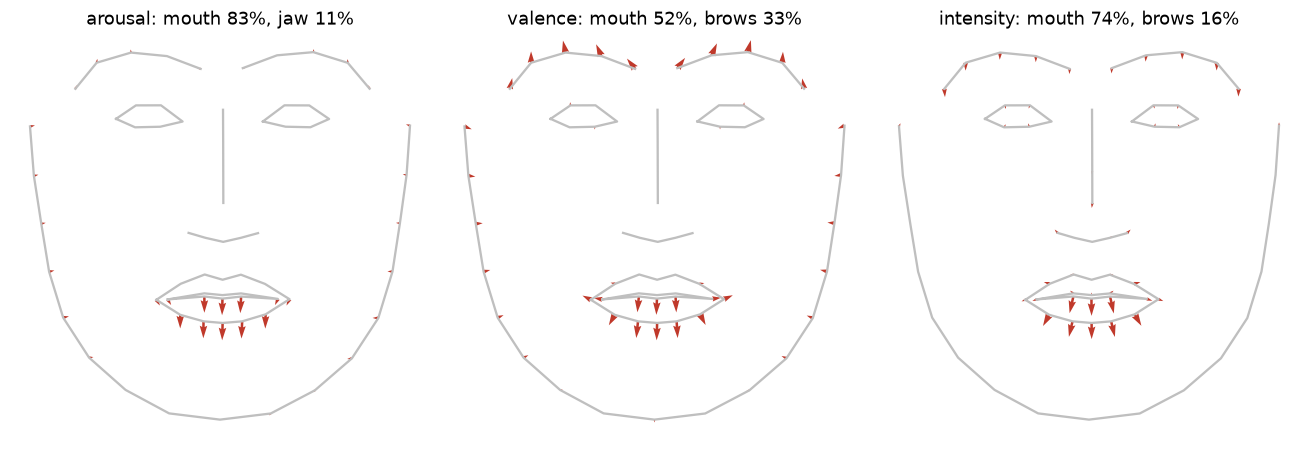

In [7]:
from facial_expression_analysis.training.interpret import movement_region_shares, plot_movement

model = result.model
frontal_all = Frontalizer()(data.landmarks[orig])
mean_face = frontal_all[(meta.label == "NE").to_numpy()[orig]].mean(0)
pred = model.predict_features(X)
L = frontal_all.reshape(len(frontal_all), -1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for t, (ax, name) in enumerate(zip(axes, ("arousal", "valence", "intensity"), strict=True)):
    yt = pred[:, t] - pred[:, t].mean()
    move = ((L - L.mean(0)).T @ yt / (yt @ yt)).reshape(68, 2)
    top = movement_region_shares(move).sort_values(ascending=False).head(2)
    plot_movement(
        ax, mean_face, move, title=f"{name}: " + ", ".join(f"{r} {v:.0%}" for r, v in top.items())
    )
plt.tight_layout()

Arousal is driven mostly by opening the mouth, valence by the lip corners and the brows.
This is useful, and it also explains a limitation: talking or yawning will read as aroused.

## 6. Using the model on a photo

The trained model plugs straight into the estimator. The bundled model (the default when no
model is given) was trained the same way.

this notebook  Extremely delighted (A +0.52, V +0.57) | Extremely happy (A +0.28, V +0.77)
bundled        Extremely delighted (A +0.52, V +0.57) | Extremely happy (A +0.28, V +0.77)


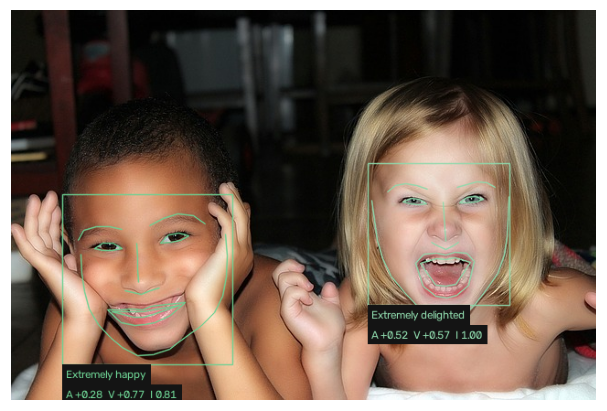

In [8]:
image = load_image(ROOT / "examples" / "kids.jpg")
detector = DlibLandmarkDetector()
for name, est in {"this notebook": EmotionEstimator(model), "bundled": EmotionEstimator()}.items():
    faces = est.analyze_image(image, detector)
    summary = [
        f"{f.emotion.label} (A {f.emotion.arousal:+.2f}, V {f.emotion.valence:+.2f})" for f in faces
    ]
    print(f"{name:14s}", " | ".join(summary))

plt.figure(figsize=(7, 4.6))
plt.imshow(annotate_image(image, EmotionEstimator(model).analyze_image(image, detector)))
plt.axis("off");

## Where to go next

- `experiments/` reproduces every claim in the README: feature choices, model comparison,
  frontalization, error analysis, behavioural tests and landmark tracking.
- The [model card](../MODEL_CARD.md) covers evaluation, calibration and limitations.
- `scripts/web_demo.sh` runs the live demo with your webcam.